### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_GBHJGFNNKQVW


### Import stuff

In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from nptdms import TdmsFile
import h5py
import cv2
import glob, os
from roifile import roiread

In [4]:
import sys
sys.path.append("/home/t/tomoyuki-mano1/projects/OL_calcium")
from calfuncs.io import read_sync_ttl
from calfuncs.lsn import get_ett_vectorized, plot_lsn_response, analyze_rf, plot_rf, fit_vector_field, plot_retinotopy, plot_vector_field

In [5]:
from matplotlib import font_manager
import matplotlib as mpl

font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

In [6]:
### PARAMETERS ####
UM_PER_PIXEL = 0.52
DEGREE_PER_PIXEL = 2.0

In [7]:
#### path to relevant files
rootdir = "/bucket/ReiterU/OLdev/experiments/20250317_squid_cal520"
recname = "rec6"
savedir = "/bucket/ReiterU/OLdev/analysis/20250327_OGL_receptive_field/20250317_rec6/plots"

templatefile = os.path.join(rootdir, "2P", recname, "run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif")
roifile = os.path.join(rootdir, "2P", recname, "ROI_yutaka_renamed.zip")
dfffile = os.path.join(rootdir, "2P", recname, "dff_ROI_yutaka/DFF.hdf5")
syncfile = os.path.join(rootdir, "sync", f"{recname}.tdms")
lsn_matrix_file = "/bucket/ReiterU/OLdev/experiments/visual_stim/20241021_LSN_matrix/LSN_2DEG.npy"

### Load relevant files

In [8]:
sync_ttl = read_sync_ttl(syncfile)
twop_ttl = sync_ttl["twop_ttl"]
twop_re = sync_ttl["twop_re"]
vis_re = sync_ttl["vis_re"]
print(twop_ttl.shape, twop_re.shape, vis_re.shape)

(1238000,) (18851,) (1240,)


In [9]:
with h5py.File(dfffile, "r") as hf:
    # Y = hf["dff"][:]
    Y = hf["F"][:]
print(Y.shape) # Y is sampled at 1 kHz

(276, 1238000)


In [10]:
lsn_mat = np.load(lsn_matrix_file)
# flip x
lsn_mat = lsn_mat[:, :, ::-1]

print(lsn_mat.shape)

(1240, 31, 55)


In [11]:
template = cv2.imread(templatefile, -1)

In [12]:
rois = roiread(roifile)
rois = sorted(rois, key=lambda x: x.name)  # sort the list
contours = [r.subpixel_coordinates.astype("int") for r in rois]
coms = np.array([r.subpixel_coordinates.mean(axis=0) for r in rois])

## ETA for locally sparse noise (LSN)

In [13]:
%%time
E = []
for nid in np.arange(Y.shape[0]):
# for nid in np.arange(10):
    ett = get_ett_vectorized(Y, vis_re[0:1240], lsn_mat, nid, 2000, 4000, DEGREE_PER_PIXEL, mode="both", pixel_coordinate="center_origin", subsampling=50)
    ett["neuron"] = nid
    ett = ett.reset_index().set_index(["neuron", "y", "x", "trial", "time"])
    E.append(ett)
E = pd.concat(E)

CPU times: user 6min 28s, sys: 6min 12s, total: 12min 40s
Wall time: 12min 45s


In [14]:
display(E)

v
neuron y     x     trial time           
0      -31.0 -55.0 0     -2000       NaN
                         -1950       NaN
                         -1900       NaN
                         -1850       NaN
                         -1800       NaN
...                                  ...
275     29.0  53.0 19     3750  0.013332
                          3800  0.027190
                          3850 -0.083065
                          3900 -0.270103
                          3950 -0.212823

[1108857600 rows x 1 columns]

In [ ]:
rf_result = []

for nid in range(Y.shape[0]):
# for nid in range(10):
    print(nid)
    # plot_lsn_response(E, nid, 0, 1000, vmin=-0.05, vmax=0.4, cmap_name="viridis")
    rf =  analyze_rf(E, nid, 0, 1000, DEGREE_PER_PIXEL, peak_thresh=3.0, blob_thresh=2.5, sigma=0.8)
    # plot_rf(E, nid, rf, 0, 1000)
    rf_result.append({
        "neuron": nid,
        "azimuth": rf["loc_screen"][1],
        "elevation": rf["loc_screen"][0],
        "size": rf["size"],
        "x": coms[nid, 0] * UM_PER_PIXEL,
        "y": coms[nid, 1] * UM_PER_PIXEL,
    })

R = pd.DataFrame(rf_result)

In [57]:
R = pd.DataFrame(rf_result)

In [58]:
R["test"] = True
cond1 = R["size"] == 0
cond2 = (R["azimuth"] < -48) | (R["azimuth"] > -20)
cond3 = (R["elevation"] < -15) | (R["elevation"] > 10)
bad_index = R.index[cond1 | cond2 | cond3].tolist()
R.loc[bad_index, "test"] = False

In [59]:
display(R)

,neuron,azimuth,elevation,size,x,y,test
0,0,-29.500000,-1.250000,32.0,13.097500,29.661667,True
1,1,-30.466667,-1.400000,60.0,41.515881,24.753529,True
2,2,-30.666667,-1.333333,72.0,67.116661,19.576666,True
3,3,-31.400000,-1.400000,60.0,70.750587,33.104118,True
4,4,-31.705882,-1.823529,68.0,64.419998,37.249996,True
...,...,...,...,...,...,...,...
271,271,0.000000,0.000000,0.0,62.827553,200.824005,False
272,272,-34.272727,3.000000,44.0,56.712498,224.455826,True
273,273,0.000000,0.000000,0.0,49.034374,224.964996,False
274,274,-32.142857,3.571429,28.0,41.188332,226.752487,True


In [60]:
with pd.HDFStore(os.path.join(tmpdir, "result.hdf5"), mode='w') as store:
    store.put('E', E)
    store.put('R', R)

In [61]:
# with pd.HDFStore("/bucket/ReiterU/OLdev/experiments/20250317_squid_cal520/2P/rec6/dff_ROI_yutaka/plots/result.hdf5", mode='r') as store:
#     R = store["R"]
#     E = store["E"]

### Color cells by RF location

In [62]:
R_filtered = R[R["test"]].reset_index()

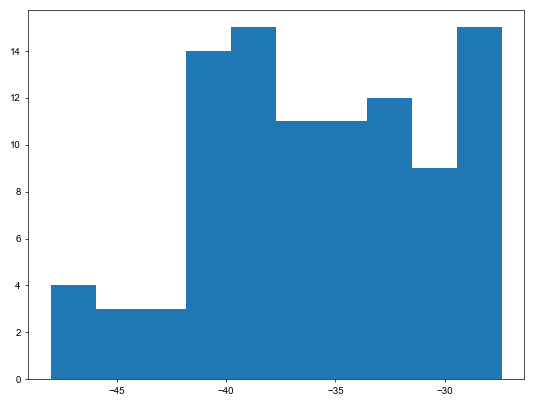

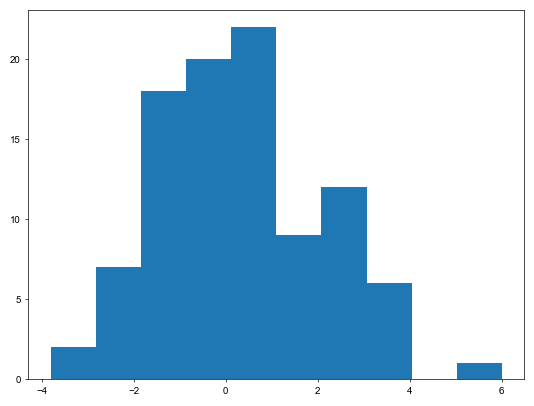

In [63]:
plt.hist(R_filtered["azimuth"])
plt.show()
plt.hist(R_filtered["elevation"])
plt.show()

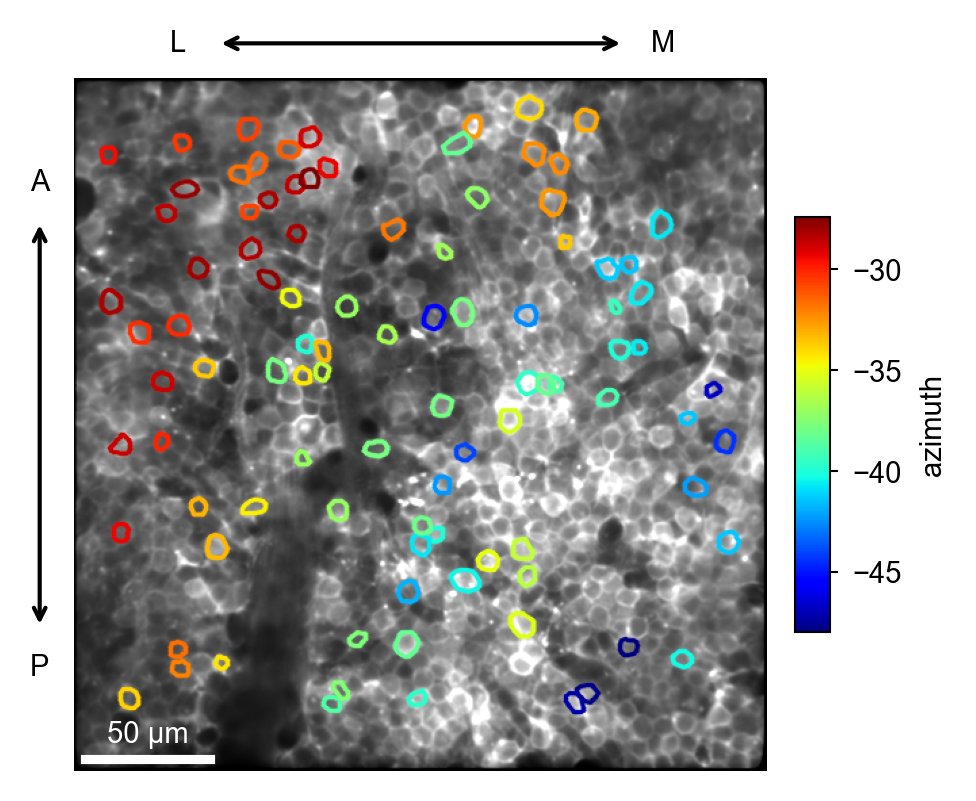

In [64]:
contours_filtered = [c for (i, c) in enumerate(contours) if i in R[R["test"]].index.to_list()]
plot_retinotopy(R_filtered, "azimuth", template, contours_filtered, show_cell_id=False, figsavename=os.path.join(tmpdir, "retinotopy_azimuth.pdf"))

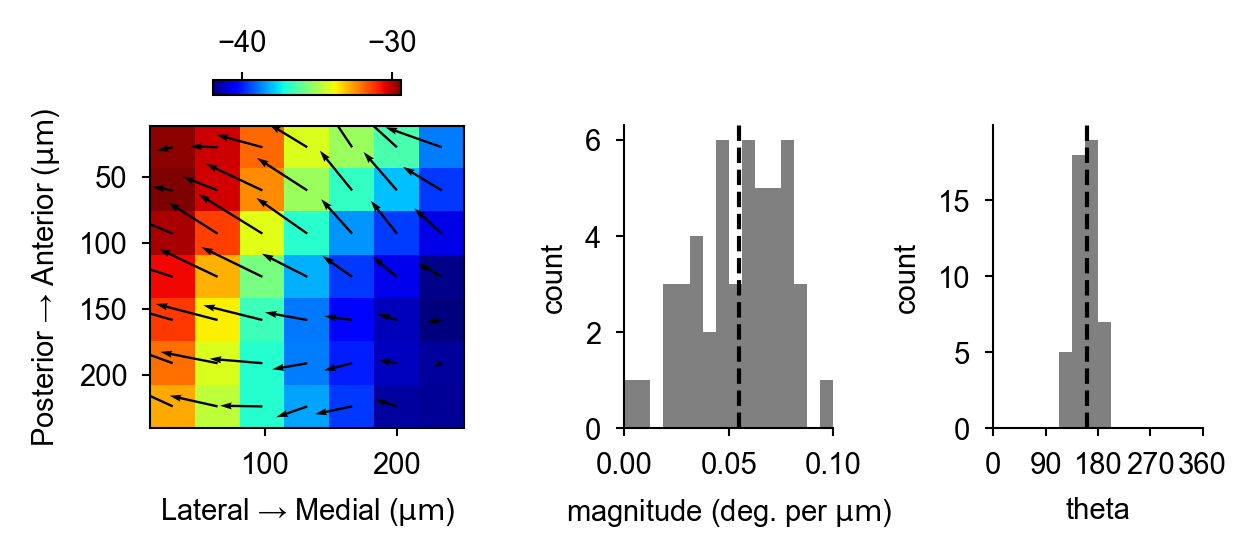

In [65]:
vfield, grad_x, grad_y, anchor_x, anchor_y = fit_vector_field(R_filtered, "azimuth", n_bins=7)
_ = plot_vector_field(R_filtered, vfield, grad_x, grad_y, anchor_x, anchor_y, figsavename=os.path.join(tmpdir, "retinotopy_vec_field_azimuth.pdf"))

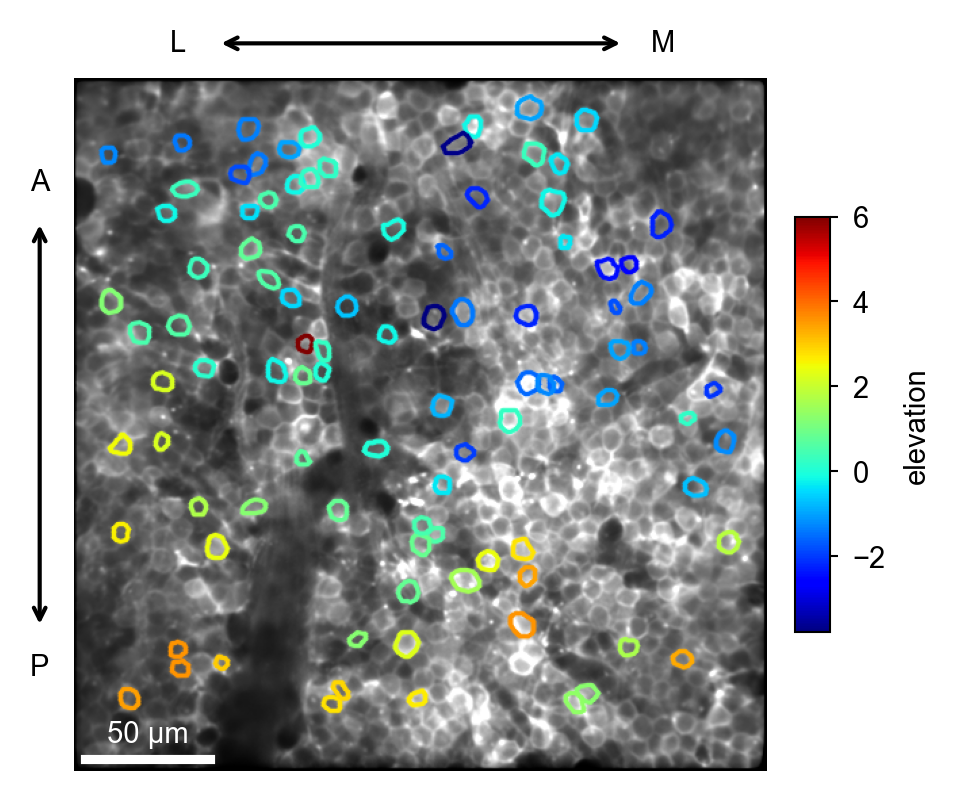

In [67]:
contours_filtered = [c for (i, c) in enumerate(contours) if i in R[R["test"]].index.to_list()]
plot_retinotopy(R_filtered, "elevation", template, contours_filtered, show_cell_id=False, figsavename=os.path.join(tmpdir, "retinotopy_elevation.pdf"))

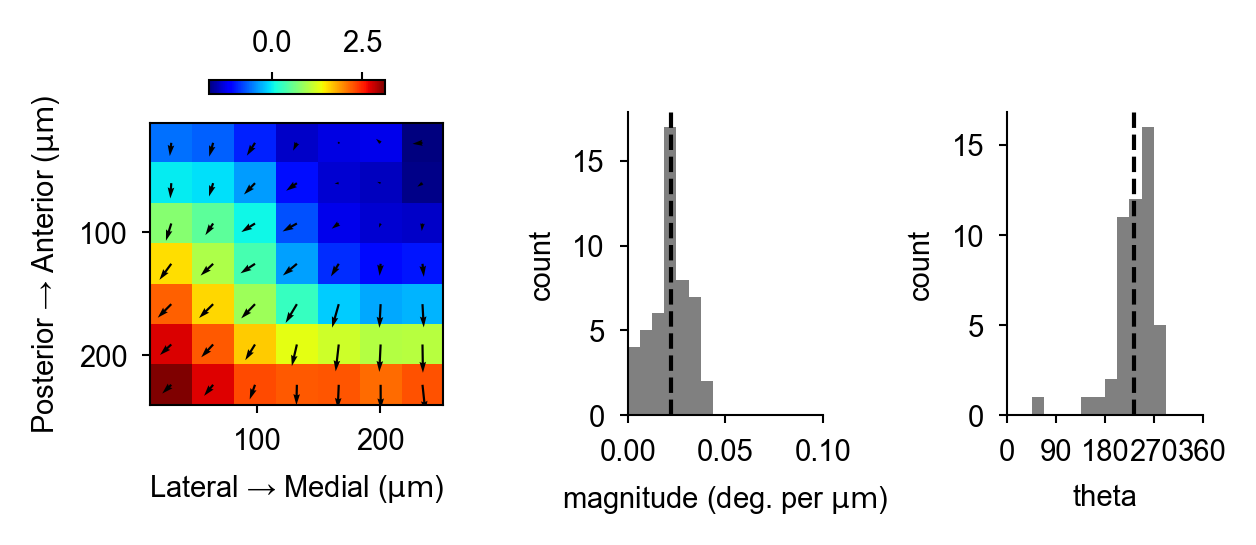

In [68]:
vfield, grad_x, grad_y, anchor_x, anchor_y = fit_vector_field(R_filtered, "elevation", n_bins=7)
_ = plot_vector_field(R_filtered, vfield, grad_x, grad_y, anchor_x, anchor_y, figsavename=os.path.join(tmpdir, "retinotopy_vec_field_elevation.pdf"))

### RF size distribution

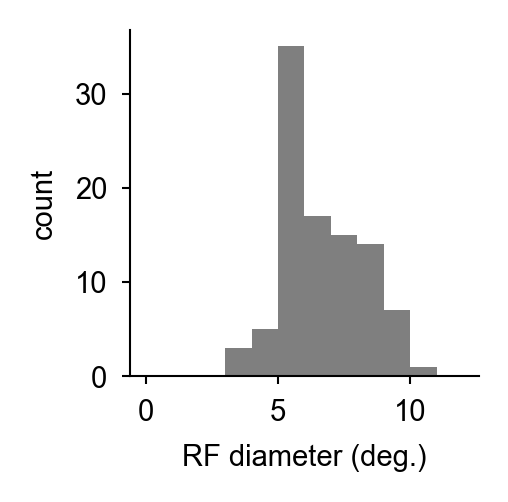

In [66]:
rf_sizes = R[R["test"]]["size"].to_numpy()
rf_diameter = 2 * np.sqrt(rf_sizes / np.pi)

count, bin_edges = np.histogram(rf_diameter, range=[0, 12], bins=12, density=False)
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

fig, ax = plt.subplots(figsize=(1.5,1.5), dpi=300)
ax.bar(bin_centers, count, width=bin_edges[1]-bin_edges[0], lw=0, alpha=0.5, color="k")
ax.set_xlabel("RF diameter (deg.)")
ax.set_ylabel("count")
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
plt.show()

### Copy data to bucket

In [54]:
print(f"mkdir -p {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir -p /bucket/ReiterU/OLdev/analysis/20250327_OGL_receptive_field/20250317_rec6/plots
cp -r /flash/ReiterU/tmp/tomo_GBHJGFNNKQVW/* /bucket/ReiterU/OLdev/analysis/20250327_OGL_receptive_field/20250317_rec6/plots
